# Nevis: RIA Market Analysis from SEC Form ADV Data
**Lianne Naimer | Data Analysis Hometask (Deployment)**

**What this notebook does**
1. Downloads the SEC's monthly Form ADV data for SEC-registered investment advisers (RIAs), one snapshot per year for the last 5 years, taken in the same month each year so every comparison is like for like.
2. Parses the messy raw files (column names and formats change between years) into one clean firm-by-year table.
3. Answers Nevis's questions by AUM segment: how many firms, who is growing fastest, who is capacity-strained, who looks under-staffed.
4. Turns that into a short list of where I would point sales and deployment first.

**How to run:** Runtime > Run all. The only setting to change is `USER_AGENT` in the config cell (the SEC asks every automated request to include a name and email). Raw files are cached in `./data` as `ria_YYYY-MM.<ext>`, so re-runs are fast. If the SEC site blocks the download, save the monthly files there by hand with that naming and re-run.

**Source:** [SEC: Information About Registered Investment Advisers and Exempt Reporting Advisers](https://www.sec.gov/data-research/sec-markets-data/information-about-registered-investment-advisers-exempt-reporting-advisers). Exempt reporting adviser files are excluded on purpose, since they are not RIAs.

## Summary (read this first)
**The question behind the task:** which RIAs should Nevis go after, and where is the pain it solves sharpest?

- **Market shape.** 17,263 SEC-registered RIAs. 69% are under $1B but hold 2% of assets; the 433 firms over $50B hold 79% (mostly institutional managers).
- **Nevis's real market is about 1,000 firms.** Wealth managers (offer financial planning, at least half of AUM from individuals) with $1B+ and 10+ advisors: roughly 1,000 firms holding about $18T.
- **Fastest growing:** across all RIAs the lists are fund launches and acquisitions. Among wealth managers, the leaders are roll-ups: Focus Partners Wealth, &Partners, Farther, Arax, Merit.
- **Capacity-strained:** some wealth managers run $700M to $2B per advisor. The median wealth manager over $1B runs about $130M per advisor.
- **Under-staffed:** about 90% of wealth managers grew assets faster than advisor headcount over 3 years. The biggest gaps sit at consolidators (Focus, Osaic, Cetera, Pathstone).
- **Timing:** 97 wealth managers with $1B+ grew their advisor team 30%+ in the last year, usually through acquisitions. That is the moment they most need one way of working, so it is the call list for this quarter.
- **Checks:** my market-wide numbers match a published Form ADV study within a few percent (median asset growth 14.4% vs 14.5%, clients per advisor 31 vs 32). Nevis's publicly announced customers (Focus, Apollon, United Capital, IEQ) land in the top quarter of the prospect score I built, without being used to build it.

**What I would do with this:** give sales the top-25 shortlist; open every first meeting with the firm's own numbers (for example, "your assets grew 64% a year over 3 years and your advisor team 25%"); and after go-live, track the same two numbers to prove the capacity gain, comparing live offices against not-yet-live offices of similar size.

In [1]:
# ---- Config ----
USER_AGENT = "Lianne Naimer (add contact email)"   # SEC asks automated requests to include a name and email
DATA_DIR = "data"
YEARS_BACK = 5
SEGMENTS = [(0, 1e9, "<$1B"), (1e9, 10e9, "$1B-$10B"), (10e9, 50e9, "$10B-$50B"), (50e9, float("inf"), ">$50B")]
SEGMENT_ORDER = [s[2] for s in SEGMENTS]

# Guardrails for ranking (explained in the Assumptions section)
MIN_BASE_AUM = 50e6        # ignore growth off a tiny starting base
MIN_ADVISORS = 3           # per-advisor metrics are noisy for 1-2 person shops
WEALTH_SHARE = 0.5         # "wealth manager" = offers financial planning AND at least half of AUM is from individuals / HNW individuals
TOP_N = 10

import os, re, io, zipfile, warnings
from datetime import date
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["text.parse_math"] = False   # so "$1B-$10B" labels print literally
pd.set_option("display.max_columns", 30, "display.width", 200, "display.float_format", "{:,.2f}".format)
os.makedirs(DATA_DIR, exist_ok=True)

def money(df):
    # Display dollar columns in $M so tables are readable (CSV exports keep full USD)
    out = df.copy()
    for c in out.columns:
        if c.startswith("aum") and "cagr" not in c:
            out[c] = (out[c] / 1e6).round(2 if "per_client" in c else 0)
    return out.rename(columns=lambda c: c + " ($M)" if c.startswith("aum") and "cagr" not in c else c)

## Step 1a: Find and download one snapshot per year
The SEC publishes a new file every month, but the file names are inconsistent (`ia110121.zip`, `ia09012026-registered.zip`, `ia110124_0.xlsx`...), formats switch between zipped CSV, zipped Excel and bare Excel, and two months (October and November 2025) were published with **no data**. So instead of parsing file names, I read the link labels on the SEC page ("Registered Investment Advisers, November 2024"), which are consistent.

I take the latest month, then the same month 1 to 5 years earlier. Same month every year means every comparison is like for like. When a month has no data, I use the nearest month and print the substitution.

In [2]:
SEC_PAGE = "https://www.sec.gov/data-research/sec-markets-data/information-about-registered-investment-advisers-exempt-reporting-advisers"
HEADERS = {"User-Agent": USER_AGENT}
MONTHS = {m: i for i, m in enumerate(["january", "february", "march", "april", "may", "june", "july", "august",
                                      "september", "october", "november", "december"], 1)}

def list_remote_files():
    # {date(year, month, 1): url} for every monthly RIA file; exempt reporting advisers excluded
    from bs4 import BeautifulSoup
    try:
        html = requests.get(SEC_PAGE, headers=HEADERS, timeout=30).text
    except Exception as e:
        print(f"SEC page not reachable from this environment ({type(e).__name__}); using cached files in ./{DATA_DIR}")
        return {}
    found, no_data = {}, []
    for a in BeautifulSoup(html, "html.parser").find_all("a", href=True):
        m = re.match(r"Registered Investment Advisers,\s*([A-Za-z]+)\s+(\d{4})", a.get_text(" ", strip=True))
        if not m or m.group(1).lower() not in MONTHS:
            continue
        d = date(int(m.group(2)), MONTHS[m.group(1).lower()], 1)
        href = a["href"] if a["href"].startswith("http") else "https://www.sec.gov" + a["href"]
        if href.lower().endswith(".pdf"):          # SEC posts a PDF notice for months with no data
            no_data.append(d.strftime("%b %Y"))
        else:
            found[d] = href
    print(f"{len(found)} monthly RIA files listed on the SEC page; months with no data: {', '.join(no_data) or 'none'}")
    return found

def list_local_files():
    # Files saved by this notebook are named ria_YYYY-MM.<ext>
    out = {}
    for f in os.listdir(DATA_DIR):
        m = re.match(r"ria_(\d{4})-(\d{2})\.(zip|xlsx|csv)$", f)
        if m:
            out[date(int(m.group(1)), int(m.group(2)), 1)] = os.path.join(DATA_DIR, f)
    return out

def months_apart(a, b):
    return abs((a.year - b.year) * 12 + a.month - b.month)

def pick_snapshots(available, years_back=YEARS_BACK):
    latest = max(available)
    picks = {0: latest}
    for k in range(1, years_back + 1):
        target = date(latest.year - k, latest.month, 1)
        best = min(available, key=lambda d: (months_apart(d, target), d < target))
        if months_apart(best, target) <= 2:
            picks[k] = best
            if best != target:
                print(f"t-{k}y: no data for {target:%b %Y}, using {best:%b %Y} instead")
    return picks

remote = list_remote_files()
local = list_local_files()
available = {**remote, **local}
assert available, f"No files found online or in ./{DATA_DIR}. Download the monthly RIA files from the SEC page."
snapshots = pick_snapshots(available)

paths = {}
for k, d in sorted(snapshots.items()):
    if d in local:
        path = local[d]
    else:
        url = available[d]
        path = os.path.join(DATA_DIR, f"ria_{d:%Y-%m}.{url.rsplit('.', 1)[-1].lower()}")
        r = requests.get(url, headers=HEADERS, timeout=300)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    paths[d] = path
    print(f"t-{k}y  {d:%b %Y}  {os.path.basename(path)}  ({os.path.getsize(path)/1e6:.1f} MB)")

SEC page not reachable from this environment (ProxyError); using cached files in ./data
t-1y: no data for Nov 2025, using Dec 2025 instead
t-0y  Nov 2026  ria_2026-11.zip  (5.4 MB)
t-1y  Dec 2025  ria_2025-12.zip  (5.1 MB)
t-2y  Nov 2024  ria_2024-11.xlsx  (20.1 MB)
t-3y  Nov 2023  ria_2023-11.xlsx  (19.5 MB)
t-4y  Nov 2022  ria_2022-11.zip  (13.7 MB)
t-5y  Nov 2021  ria_2021-11.zip  (3.4 MB)


## Step 1b: Parse each file into a clean table
Instead of hard-coding column positions, I match each field to its Form ADV item number and print the mapping for every file, so each choice can be checked.

| Field | Form ADV item | Note |
|---|---|---|
| AUM | Item 5.F(2)(c) | Total regulatory assets under management |
| Employees | Item 5.A | Total employees |
| Advisors | Item 5.B(1) | Employees who perform investment advisory functions (incl. research) |
| Clients | Item 5.D(a-n)(1) + 5.C(1) | Clients by type, plus clients with no regulatory AUM. Where a firm ticks "fewer than 5 clients" for a type (5.D(x)(2)), I count 2 |
| Wealth-manager flag | Item 5.G(1), 5.D(a)(3), 5.D(b)(3) | Offers financial planning, and share of AUM from individuals and high-net-worth individuals. Separates wealth managers (Nevis's customers) from fund managers, consultants and quant shops |

Note: on the current Form ADV, Item 5.C(1) is *not* total clients. It is the number of clients for whom the firm has **no** regulatory AUM. Total clients has to be built from Item 5.D.

In [3]:
FIELDS = {
    "crd":        [r"^organizationcrd", r"^crd"],
    "sec_no":     [r"^sec#", r"^secnumber"],
    "firm_name":  [r"^primarybusinessname"],
    "legal_name": [r"^legalname"],
    "website":    [r"^websiteaddress", r"website"],
    "city":       [r"^mainofficecity"],
    "state":      [r"^mainofficestate"],
    "filing_date":[r"^latestadvfilingdate"],
    "employees":  [r"^5a$"],
    "advisors":   [r"^5b\(1\)$"],
    "aum":        [r"^5f\(2\)\(c\)$"],
    "no_raum_clients": [r"^5c\(1\)$"],
    "offers_planning": [r"^5g\(1\)$"],
}

def norm(c):
    return re.sub(r"\s+", "", str(c)).lower()

def normed_cols(cols):
    return {norm(c): c for c in cols}

def map_columns(cols):
    normed = {norm(c): c for c in cols}
    mapping = {}
    for field, patterns in FIELDS.items():
        for p in patterns:
            hit = next((orig for n, orig in normed.items() if re.search(p, n)), None)
            if hit is not None:
                mapping[field] = hit
                break
    d_count = {n: o for n, o in normed.items() if re.fullmatch(r"5d\([a-n]\)\(1\)", n)}   # number of clients by type
    d_few = {n: o for n, o in normed.items() if re.fullmatch(r"5d\([a-n]\)\(2\)", n)}     # "fewer than 5 clients" flag
    return mapping, d_count, d_few

def to_num(s):
    # "1,234,567.00" -> 1234567.0 ; blanks -> NaN
    return pd.to_numeric(s.astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce")

def read_raw(path):
    if path.lower().endswith(".xlsx"):
        return pd.read_excel(path, dtype=str)
    if path.lower().endswith(".csv"):
        return pd.read_csv(path, dtype=str, encoding="latin-1", low_memory=False)
    with zipfile.ZipFile(path) as z:
        inner = [n for n in z.namelist() if n.lower().endswith((".xlsx", ".csv"))][0]
        data = z.read(inner)
    if inner.lower().endswith(".xlsx"):
        return pd.read_excel(io.BytesIO(data), dtype=str)
    return pd.read_csv(io.BytesIO(data), dtype=str, encoding="latin-1", low_memory=False)

def parse_snapshot(path, snap_date):
    raw = read_raw(path)
    m, d_count, d_few = map_columns(raw.columns)
    missing = [f for f in FIELDS if f not in m]
    print(f"{snap_date:%b %Y}: {len(raw):,} firms, {raw.shape[1]} columns | mapped {len(m)}/{len(FIELDS)} fields, "
          f"{len(d_count)} client-type columns" + (f" | MISSING {missing}" if missing else ""))
    out = pd.DataFrame({f: raw[c] for f, c in m.items()})
    for f in ["crd", "employees", "advisors", "aum", "no_raum_clients"]:
        if f in out:
            out[f] = to_num(out[f])

    counts = raw[list(d_count.values())].apply(to_num)
    few = raw[list(d_few.values())].notna().astype(int) * 2          # "fewer than 5" -> count 2
    few.columns = [c.replace("(2)", "(1)") for c in few.columns]
    by_type = counts.fillna(0).add(few.reindex(columns=counts.columns, fill_value=0), fill_value=0)
    total_typed = by_type.sum(axis=1)
    indiv_cols = [o for n, o in d_count.items() if n.startswith(("5d(a)", "5d(b)"))]
    out["clients"] = (total_typed + out.get("no_raum_clients", 0).fillna(0)).replace(0, np.nan)
    out["pct_individual_clients"] = np.where(total_typed > 0, by_type[indiv_cols].sum(axis=1) / total_typed, np.nan)
    indiv_aum_cols = [o for n, o in normed_cols(raw.columns).items() if re.fullmatch(r"5d\([ab]\)\(3\)", n)]
    indiv_aum = raw[indiv_aum_cols].apply(to_num).sum(axis=1, min_count=1) if indiv_aum_cols else np.nan
    out["pct_individual_aum"] = np.where(out["aum"] > 0, (indiv_aum / out["aum"]).clip(0, 1), np.nan)
    if "offers_planning" in out:
        out["offers_planning"] = out["offers_planning"].str.strip().str.upper().eq("Y")
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out["snapshot_date"] = pd.Timestamp(snap_date)
    out["snapshot_year"] = snap_date.year
    return out.drop(columns=["no_raum_clients"], errors="ignore")

frames = [parse_snapshot(p, d) for d, p in sorted(paths.items())]

Nov 2021: 14,777 firms, 262 columns | mapped 13/13 fields, 14 client-type columns


Nov 2022: 15,423 firms, 262 columns | mapped 13/13 fields, 14 client-type columns


Nov 2023: 15,573 firms, 448 columns | mapped 13/13 fields, 14 client-type columns


Nov 2024: 15,974 firms, 448 columns | mapped 13/13 fields, 14 client-type columns


Dec 2025: 16,484 firms, 448 columns | mapped 13/13 fields, 14 client-type columns


Nov 2026: 17,263 firms, 448 columns | mapped 13/13 fields, 14 client-type columns


## Step 1c: Clean and build the firm-level table
Cleaning rules (each one is counted below so nothing is dropped silently):
- One row per firm per snapshot. Firms are keyed on **CRD number** (the SEC's permanent firm ID), not name, because firms rename and rebrand.
- SEC# standardized to the `801-XXXXX` format; websites standardized to `www.domain.com`.
- AUM per client and AUM per advisor are only calculated when the denominator is above zero.

In [4]:
def clean_sec(s):
    s = str(s).strip()
    m = re.search(r"(\d{3})-?(\d{1,6})", s)
    return f"{m.group(1)}-{m.group(2)}" if m else np.nan

SOCIAL = r"linkedin|facebook|twitter|instagram|youtube|pinterest|tiktok|apple\.com|spotify|vimeo|^www\.x\.com|medium\.com|threads\.net|amazon\.com|soundcloud|podcast|substack|yelp|google\.com"

def clean_web(s):
    if pd.isna(s) or not str(s).strip():
        return np.nan
    first = re.split(r"[\s,;|]+", str(s).strip())[0].lower()
    first = re.sub(r"^https?://", "", first).split("/")[0]
    return first if first.startswith("www.") else "www." + first

panel = pd.concat(frames, ignore_index=True)
log = {"raw rows": len(panel)}
panel = panel.dropna(subset=["crd"])
log["after dropping rows with no CRD"] = len(panel)
panel = (panel.sort_values(["crd", "snapshot_date", "filing_date"])
              .drop_duplicates(["crd", "snapshot_date"], keep="last"))
log["after de-duplicating firm x snapshot"] = len(panel)
panel = panel[panel["aum"].isna() | (panel["aum"] >= 0)]
log["after dropping negative AUM"] = len(panel)

panel["crd"] = panel["crd"].astype("int64")
panel["sec_no"] = panel["sec_no"].map(clean_sec) if "sec_no" in panel else np.nan
panel["website"] = panel["website"].map(clean_web)
# The SEC export carries only one of each firm's listed websites, and it is often a social profile.
# Keep the firm's own domain, and borrow it from another year's filing when the latest one is social.
panel.loc[panel["website"].str.contains(SOCIAL, na=False), "website"] = np.nan
panel["website"] = panel.groupby("crd")["website"].transform(lambda s: s.bfill().ffill())
panel["firm_name"] = panel["firm_name"].str.strip().str.title()
panel["state"] = panel["state"].str.strip().str.upper()
panel["city"] = panel["city"].str.strip().str.title()
panel["aum_per_client"] = np.where(panel["clients"] > 0, panel["aum"] / panel["clients"], np.nan)
panel["aum_per_advisor"] = np.where(panel["advisors"] > 0, panel["aum"] / panel["advisors"], np.nan)
panel["clients_per_advisor"] = np.where(panel["advisors"] > 0, panel["clients"] / panel["advisors"], np.nan)
panel["filing_year"] = panel["filing_date"].dt.year
panel["segment"] = pd.cut(panel["aum"].fillna(0), [s[0] for s in SEGMENTS] + [float("inf")],
                          labels=SEGMENT_ORDER, right=False)
panel["wealth_focused"] = panel["offers_planning"].fillna(False).astype(bool) & panel["pct_individual_aum"].ge(WEALTH_SHARE)

for k, v in log.items():
    print(f"{k:<40}{v:>10,}")

COLS = ["sec_no", "firm_name", "website", "city", "state", "aum", "clients", "aum_per_client",
        "employees", "advisors", "aum_per_advisor", "clients_per_advisor", "pct_individual_clients", "pct_individual_aum", "offers_planning",
        "filing_date", "filing_year", "snapshot_date", "segment", "wealth_focused", "crd"]
firm_table = panel[COLS].sort_values(["snapshot_date", "aum"], ascending=[True, False]).reset_index(drop=True)
firm_table.to_csv("ria_firm_table.csv", index=False)
LATEST = firm_table["snapshot_date"].max()
latest = firm_table[firm_table["snapshot_date"] == LATEST].copy()
print(f"\nLatest snapshot: {LATEST.date()} | {len(latest):,} RIAs | saved full table to ria_firm_table.csv")
money(latest.head(10))

raw rows                                    95,494
after dropping rows with no CRD             95,494
after de-duplicating firm x snapshot        95,494
after dropping negative AUM                 95,494



Latest snapshot: 2026-11-01 | 17,263 RIAs | saved full table to ria_firm_table.csv


,sec_no,firm_name,website,city,state,aum ($M),clients,aum_per_client ($M),employees,advisors,aum_per_advisor ($M),clients_per_advisor,pct_individual_clients,pct_individual_aum,offers_planning,filing_date,filing_year,snapshot_date,segment,wealth_focused,crd
78231,801-11953,Vanguard Group Inc,NaN,Malvern,PA,"11,092,665.00",228.00,"48,652.04","1,702.00",19.00,"583,824.00",12.00,0.00,0.00,False,2026-10-16,2026,2026-11-01,>$50B,False,105958
78232,801-134586,"Vanguard Capital Management, Llc",NaN,Malvern,PA,"8,436,182.00",128.00,"65,907.67",235.00,235.00,"35,899.00",0.54,0.00,0.00,False,2026-09-21,2026,2026-11-01,>$50B,False,338002
78233,801-7884,Fidelity Management & Research Company Llc,NaN,Boston,MA,"5,685,042.00","36,653.00",155.10,"1,427.00",744.00,"7,641.00",49.26,0.98,0.00,False,2026-07-30,2026,2026-11-01,>$50B,False,108281
78234,801-8055,Capital Research And Management Company,www.retirementsolutions.financialtrans.com,Los Angeles,CA,"4,320,750.00","23,712.00",182.22,"1,395.00",411.00,"10,513.00",57.69,0.98,0.00,False,2026-09-25,2026,2026-11-01,>$50B,False,110885
78235,801-22609,Blackrock Fund Advisors,NaN,San Francisco,CA,"4,282,224.00",531.00,"8,064.45",128.00,122.00,"35,100.00",4.35,0.00,NaN,False,2026-10-02,2026,2026-11-01,>$50B,False,105247
78236,801-48187,Pacific Investment Management Company Llc,www.pimco.com,Newport Beach,CA,"3,666,935.00","41,704.00",87.93,"1,968.00",628.00,"5,839.00",66.41,0.14,0.01,False,2026-10-23,2026,2026-11-01,>$50B,False,104559
78237,801-21011,J.P. Morgan Investment Management Inc.,www.am.jpmorgan.com,New York,NY,"3,519,415.00","129,024.00",27.28,"3,194.00","2,260.00","1,557.00",57.09,0.00,0.00,False,2026-08-26,2026,2026-11-01,>$50B,False,107038
78238,801-134587,"Vanguard Portfolio Management, Llc",NaN,Malvern,PA,"2,656,484.00",101.00,"26,301.82",105.00,105.00,"25,300.00",0.96,0.00,0.00,False,2026-09-21,2026,2026-11-01,>$50B,False,338003
78239,801-37591,"Goldman Sachs Asset Management, L.P.",www.petershillpartners.com,New York,NY,"2,648,903.00","121,430.00",21.81,"2,059.00","1,379.00","1,921.00",88.06,0.87,0.14,False,2026-09-25,2026,2026-11-01,>$50B,False,107738
78240,801-856,"T. Rowe Price Associates, Inc.",www.troweprice.com,Baltimore,MD,"2,196,453.00","6,974.00",314.95,"3,760.00",545.00,"4,030.00",12.80,0.12,0.00,False,2026-07-06,2026,2026-11-01,>$50B,False,105496


### Data quality checks

In [5]:
checks = pd.DataFrame({
    "firms": firm_table.groupby("snapshot_date")["crd"].nunique(),
    "total AUM ($T)": firm_table.groupby("snapshot_date")["aum"].sum() / 1e12,
    "% with AUM": firm_table.groupby("snapshot_date")["aum"].apply(lambda s: s.notna().mean() * 100),
    "% with advisors": firm_table.groupby("snapshot_date")["advisors"].apply(lambda s: s.notna().mean() * 100),
    "% with clients": firm_table.groupby("snapshot_date")["clients"].apply(lambda s: s.notna().mean() * 100),
    "% with website": firm_table.groupby("snapshot_date")["website"].apply(lambda s: s.notna().mean() * 100),
})
assert not firm_table.duplicated(["crd", "snapshot_date"]).any(), "duplicate firm-snapshot rows"
assert (firm_table["aum"].dropna() >= 0).all()
checks

,firms,total AUM ($T),% with AUM,% with advisors,% with clients,% with website
snapshot_date,,,,,,
2021-11-01,14777,112.70,100.00,99.99,97.04,81.36
2022-11-01,15423,127.57,100.00,99.99,97.20,81.88
2023-11-01,15573,125.76,100.00,99.99,97.26,82.14
2024-11-01,15974,128.72,100.00,99.99,97.40,82.05
2025-12-01,16484,144.68,100.00,99.99,97.73,81.28
2026-11-01,17263,177.86,100.00,99.99,97.81,79.65


In [6]:
# Spot check against a firm named in the brief: does the history look right?
firm_table[firm_table["firm_name"].str.contains("Beacon Pointe", case=False, na=False)][
    ["snapshot_date", "sec_no", "firm_name", "website", "aum", "clients", "advisors", "aum_per_advisor"]]

,snapshot_date,sec_no,firm_name,website,aum,clients,advisors,aum_per_advisor
936,2021-11-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"12,441,991,820.00","6,010.00",141.00,"88,241,076.74"
15430,2022-11-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"23,674,542,188.00","10,759.00",200.00,"118,372,710.94"
30817,2023-11-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"23,245,734,845.00","13,436.00",230.00,"101,068,412.37"
46304,2024-11-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"31,279,960,486.00","15,051.00",296.00,"105,675,542.18"
62212,2025-12-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"39,839,757,384.00","18,646.00",355.00,"112,224,668.69"
78634,2026-11-01,801-60943,"Beacon Pointe Advisors, Llc",NaN,"54,872,534,714.00","30,198.00",440.00,"124,710,306.17"


Cross-check against public reporting: Focus Partners Wealth (Focus Financial's RIA unit) shows about $182B here, matching the figure InvestmentNews reported in October 2026. The firm count and total AUM by year move smoothly, with no jumps that would point to a parsing error.

### Benchmark against published research
To check the whole pipeline, not just one firm, I compared my numbers with a published study built from the same Form ADV filings (Paithos Research, *RIA Signals Report*, Q3 2026, covering fiscal 2025, as reported by InvestmentNews). Their "advisory-function employee" is the same Item 5.B(1) definition I use for advisors.

In [7]:
fy = pd.Timestamp(snapshots[0])                       # latest filings reflect fiscal 2025
prev = pd.Timestamp(snapshots.get(1, snapshots[0]))
now_ = firm_table[(firm_table["snapshot_date"] == fy) & (firm_table["advisors"] > 0) & (firm_table["aum"] > 0)].set_index("crd")
then_ = firm_table[firm_table["snapshot_date"] == prev].set_index("crd")
j = now_.join(then_[["aum", "advisors"]], rsuffix="_prev", how="inner")
j = j[(j["aum_prev"] > 0) & (j["advisors_prev"] > 0)]
pd.DataFrame({
    "published (Paithos, FY2025)": ["14.5%", "$108.5M", "32", "56.7%"],
    "this notebook": [f"{(j['aum'] / j['aum_prev'] - 1).median():.1%}",
                      f"${now_['aum_per_advisor'].median() / 1e6:,.1f}M",
                      f"{now_['clients_per_advisor'].median():.0f}",
                      f"{((j['aum'] > j['aum_prev']) & (j['advisors'] <= j['advisors_prev'])).mean():.1%}"],
}, index=["median 1-yr AUM growth", "AUM per advisor (median)", "clients per advisor (median)",
          "% of firms growing AUM with flat or lower headcount"])

,"published (Paithos, FY2025)",this notebook
median 1-yr AUM growth,14.5%,14.4%
AUM per advisor (median),$108.5M,$102.9M
clients per advisor (median),32,31
% of firms growing AUM with flat or lower headcount,56.7%,57.0%


## Step 2: Market segments (latest snapshot)

In [8]:
seg = latest.groupby("segment", observed=False).agg(
    firms=("crd", "count"),
    total_aum_bn=("aum", lambda s: s.sum() / 1e9),
    median_aum_mn=("aum", lambda s: s.median() / 1e6),
    median_advisors=("advisors", "median"),
    wealth_focused_firms=("wealth_focused", "sum"),
)
seg["% of firms"] = seg["firms"] / seg["firms"].sum() * 100
seg["% of AUM"] = seg["total_aum_bn"] / seg["total_aum_bn"].sum() * 100
print(f"Firms reporting $0 regulatory AUM (counted in <$1B): {(latest['aum'].fillna(0) == 0).sum():,}")
seg

Firms reporting $0 regulatory AUM (counted in <$1B): 679


,firms,total_aum_bn,median_aum_mn,median_advisors,wealth_focused_firms,% of firms,% of AUM
segment,,,,,,,
<$1B,11873,"3,666.97",238.71,3.00,5945,68.78,2.06
$1B-$10B,4020,"12,388.20","2,264.89",12.00,1215,23.29,6.97
$10B-$50B,937,"20,791.00","18,905.17",37.00,123,5.43,11.69
>$50B,433,"141,008.96","125,408.49",127.00,48,2.51,79.28


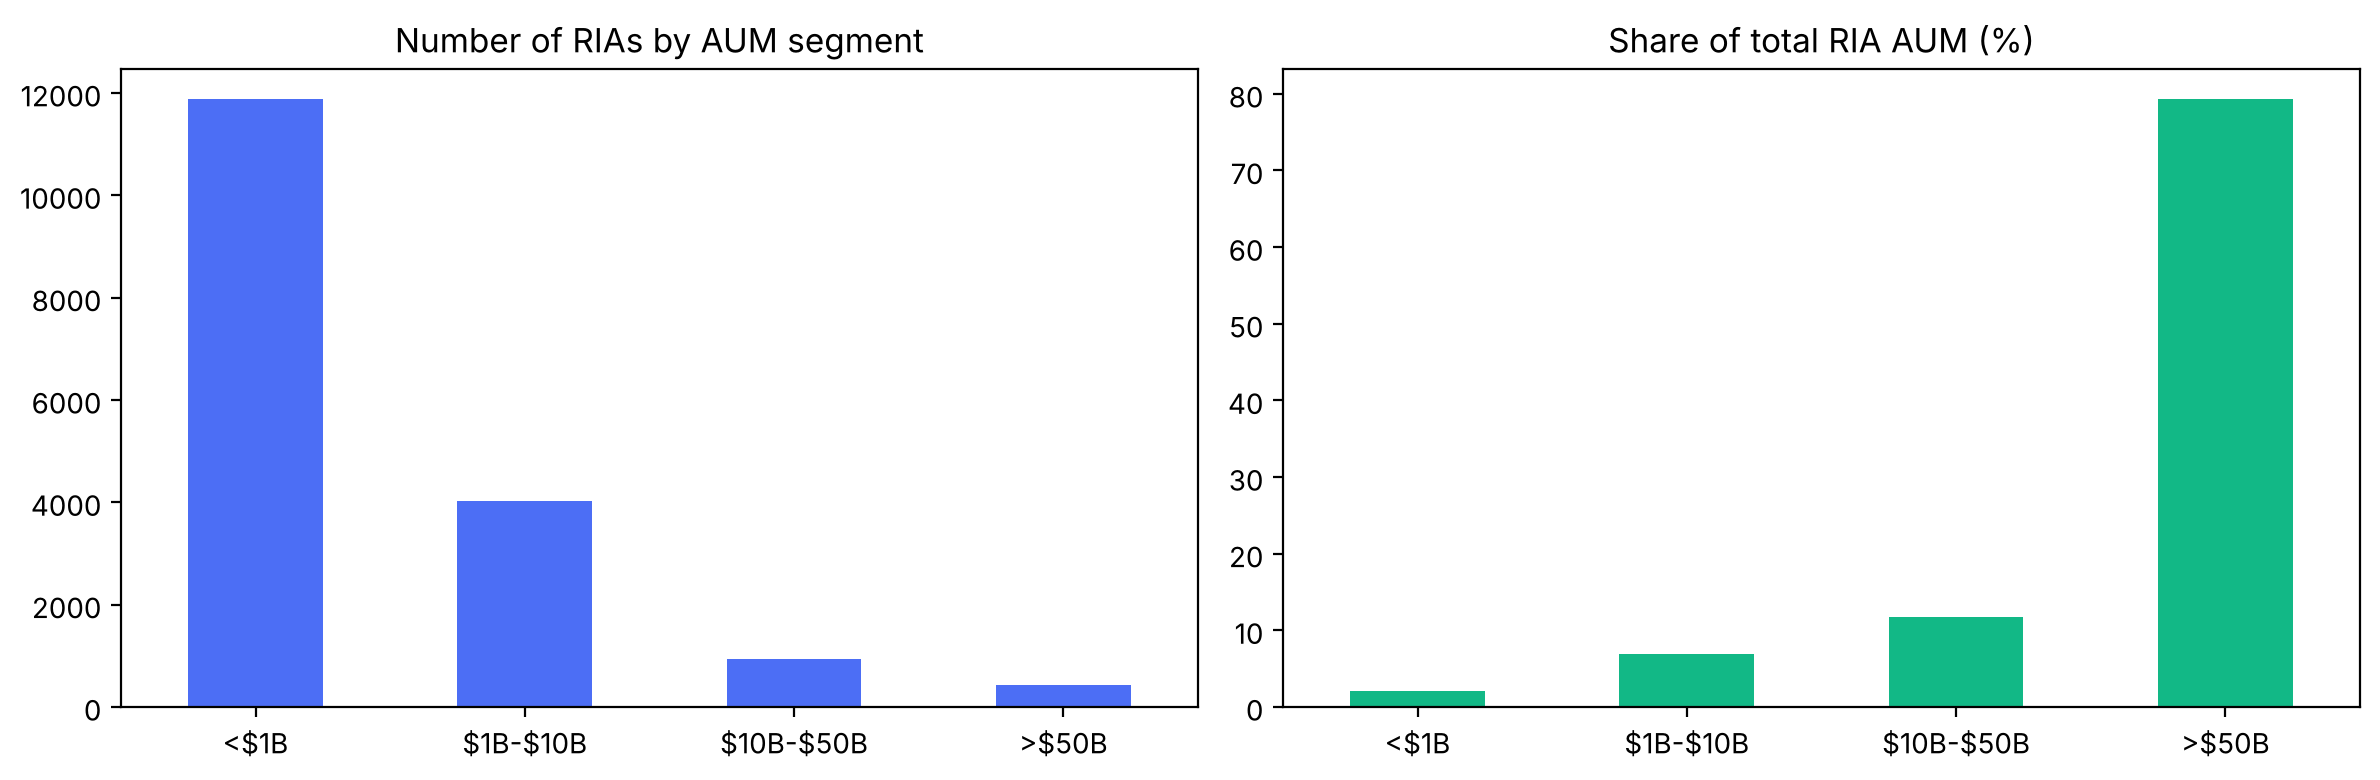

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
seg["firms"].plot.bar(ax=ax[0], color="#4C6EF5", title="Number of RIAs by AUM segment")
seg["% of AUM"].plot.bar(ax=ax[1], color="#12B886", title="Share of total RIA AUM (%)")
for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## Growth metrics (1, 3 and 5 years)
For each firm I join the latest snapshot to the same firm (same CRD) 1, 3 and 5 years earlier and compute:
- **AUM CAGR** = (AUM now / AUM then)^(1/years) - 1
- **Advisor CAGR**, same formula on Item 5.B(1)
- **Staffing gap** = AUM CAGR minus advisor CAGR. Positive means assets are growing faster than the people serving them.

Market moves lift every firm's AUM, so I also show each firm's growth **relative to the median firm in its segment** (excess growth). That separates firms that are actually winning clients from firms that just rode the market.

In [10]:
def cagr(now, then, years):
    ok = (then > 0) & (now > 0)
    return np.where(ok, (now / then) ** (1 / years) - 1, np.nan)

growth = latest.set_index("crd")
by_snap = {d: g.set_index("crd") for d, g in firm_table.groupby("snapshot_date")}
for k, d in sorted(snapshots.items()):
    if k == 0 or pd.Timestamp(d) not in by_snap:
        continue
    then = by_snap[pd.Timestamp(d)]
    growth[f"aum_{k}y_ago"] = then["aum"]
    growth[f"advisors_{k}y_ago"] = then["advisors"]
    growth[f"aum_cagr_{k}y"] = cagr(growth["aum"], growth[f"aum_{k}y_ago"], k)
    growth[f"adv_cagr_{k}y"] = cagr(growth["advisors"], growth[f"advisors_{k}y_ago"], k)
    growth[f"gap_{k}y"] = growth[f"aum_cagr_{k}y"] - growth[f"adv_cagr_{k}y"]
    seg_median = growth.groupby("segment", observed=False)[f"aum_cagr_{k}y"].transform("median")
    growth[f"excess_aum_cagr_{k}y"] = growth[f"aum_cagr_{k}y"] - seg_median
HORIZONS = [k for k in (1, 3, 5) if f"aum_cagr_{k}y" in growth]
growth = growth.reset_index()
print("Horizons available:", HORIZONS)
growth.groupby("segment", observed=False)[[f"aum_cagr_{k}y" for k in HORIZONS]].median().mul(100).round(1).rename(
    columns=lambda c: c.replace("aum_cagr_", "median AUM CAGR % ")
)

Horizons available: [1, 3, 5]


,median AUM CAGR % 1y,median AUM CAGR % 3y,median AUM CAGR % 5y
segment,,,
<$1B,14.10,13.20,8.40
$1B-$10B,15.00,14.50,11.60
$10B-$50B,14.10,12.60,10.40
>$50B,15.30,13.70,10.90


In [11]:
def pct(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = (out[c] * 100).round(1)
    return out

def show_by_segment(df, sort_col, cols, title, ascending=False):
    for s in SEGMENT_ORDER:
        sub = df[df["segment"] == s].sort_values(sort_col, ascending=ascending).head(TOP_N)
        print(f"\n{title} | {s} | {len(df[df['segment'] == s]):,} eligible firms")
        display(money(sub[cols].reset_index(drop=True)))

## Q1: Who are the fastest growing firms?
Ranked by AUM CAGR within each segment. To keep the lists meaningful:
- Firms must have started the period with at least $50M AUM (otherwise a $5M to $60M firm tops every list).
- I flag likely **acquisitions / roll-ups**: AUM more than doubling in a single year usually means a merger, not organic growth. These are still real growth, and roll-ups are especially relevant to Nevis (see takeaways).

In [12]:
for k in HORIZONS:
    elig = growth[(growth[f"aum_{k}y_ago"] >= MIN_BASE_AUM) & growth[f"aum_cagr_{k}y"].notna()].copy()
    elig["likely_M&A"] = (elig[f"aum_cagr_{k}y"] > 1.0) if k == 1 else (elig["aum"] / elig[f"aum_{k}y_ago"] > 2 ** k)
    cols = ["firm_name", "state", f"aum_{k}y_ago", "aum", f"aum_cagr_{k}y", f"excess_aum_cagr_{k}y", "advisors", "likely_M&A", "wealth_focused"]
    show_by_segment(pct(elig, [f"aum_cagr_{k}y", f"excess_aum_cagr_{k}y"]), f"aum_cagr_{k}y", cols,
                    f"Fastest growing ({k}-yr AUM CAGR, %)")


Fastest growing (1-yr AUM CAGR, %) | <$1B | 9,247 eligible firms


,firm_name,state,aum_1y_ago ($M),aum ($M),aum_cagr_1y,excess_aum_cagr_1y,advisors,likely_M&A,wealth_focused
0,"Davern Capital Partners, Lp",NY,58.00,715.00,"1,143.10","1,129.00",3.00,True,False
1,"Bitwise Investment Manager, Llc",CA,68.00,722.00,965.40,951.30,6.00,True,False
2,"Redblack Advisers, Inc.",NJ,124.00,824.00,564.20,550.10,3.00,True,False
3,Syntheticfi Llc,CA,153.00,993.00,548.10,534.00,7.00,True,False
4,Destiny Advisors Llc,TX,70.00,441.00,530.10,516.00,1.00,True,False
5,"Ara Gc Partners, Llc",TX,150.00,936.00,524.00,509.90,9.00,True,False
6,Peachtree Group,GA,156.00,941.00,504.10,490.00,69.00,True,False
7,"Wisdomtree Digital Management, Inc.",NY,129.00,766.00,494.00,479.90,3.00,True,False
8,"Millennial Advisers, Llc.",NY,59.00,339.00,478.50,464.40,12.00,True,False
9,Waystone Asset Management (Usa) Llc,IL,131.00,743.00,467.10,453.00,4.00,True,False



Fastest growing (1-yr AUM CAGR, %) | $1B-$10B | 3,945 eligible firms


,firm_name,state,aum_1y_ago ($M),aum ($M),aum_cagr_1y,excess_aum_cagr_1y,advisors,likely_M&A,wealth_focused
0,Capitolis Advisors Llc,NY,100.00,"4,500.00","4,388.50","4,373.50",10.00,True,False
1,Ratson Advisory Llc,NY,85.00,"2,388.00","2,694.00","2,679.00",1.00,True,False
2,Seabury Capital Management Llc,NY,120.00,"3,020.00","2,416.70","2,401.70",6.00,True,False
3,Situational Awareness Lp,CA,383.00,"9,278.00","2,322.40","2,307.40",4.00,True,False
4,Tremblant Advisors Lp,FL,147.00,"3,272.00","2,131.30","2,116.30",10.00,True,False
5,Unifi Asset Management Lp,NY,120.00,"2,542.00","2,017.80","2,002.80",6.00,True,False
6,"Value Aligned Research Advisors, Llc",NaN,542.00,"9,140.00","1,585.80","1,570.80",6.00,True,False
7,Xcelsior Advisor Partners Llc,AZ,150.00,"2,511.00","1,573.60","1,558.60",22.00,True,True
8,50T Funds,NY,103.00,"1,660.00","1,509.00","1,494.00",11.00,True,False
9,"Saba Lt, Lp",NY,178.00,"2,833.00","1,488.10","1,473.10",6.00,True,False



Fastest growing (1-yr AUM CAGR, %) | $10B-$50B | 925 eligible firms


,firm_name,state,aum_1y_ago ($M),aum ($M),aum_cagr_1y,excess_aum_cagr_1y,advisors,likely_M&A,wealth_focused
0,Clearbrook Investment Consulting Llc,NY,470.00,"13,719.00","2,818.30","2,804.20",6.00,True,False
1,"Openarc Corporate Advisory, Llc",GA,444.00,"10,095.00","2,175.10","2,161.00",80.00,True,True
2,"Pacific Way Capital Management, Llc",NY,"1,695.00","33,567.00","1,879.80","1,865.70",4.00,True,False
3,1823 Partners (Us) Llc,FL,"1,000.00","18,532.00","1,753.20","1,739.10",30.00,True,False
4,W1M Wealth Management Limited,NaN,"1,994.00","24,847.00","1,146.30","1,132.20",99.00,True,False
5,Canterbury Consulting Incorporated,CA,"7,391.00","45,876.00",520.70,506.60,25.00,True,False
6,"Vestmark Advisory Solutions, Inc.",MA,"10,019.00","49,855.00",397.60,383.50,25.00,True,False
7,Cfi Partners,IL,"6,239.00","26,313.00",321.80,307.70,23.00,True,False
8,Neos Investments,CT,"5,934.00","21,687.00",265.50,251.40,2.00,True,False
9,Allspring Global Investments (Uk) Limited,NaN,"10,245.00","30,793.00",200.60,186.50,29.00,True,False


... (14 outputs left out)


Fastest growing (5-yr AUM CAGR, %) | $10B-$50B | 850 eligible firms


,firm_name,state,aum_5y_ago ($M),aum ($M),aum_cagr_5y,excess_aum_cagr_5y,advisors,likely_M&A,wealth_focused
0,Stepstone Private Wealth,NC,115.00,"17,934.00",174.40,164.10,0.00,True,False
1,"Mercury Advisory, Llc",CA,183.00,"22,568.00",162.00,151.60,4.00,True,False
2,Fiduciary Consulting Group,CO,127.00,"14,731.00",158.80,148.40,33.00,True,False
3,&Partners,TN,482.00,"30,269.00",128.80,118.50,439.00,True,True
4,First Sentier Investors (Uk) Funds Limited,NaN,199.00,"11,868.00",126.60,116.20,50.00,True,False
5,Arin Risk Advisors Llc,PA,215.00,"10,186.00",116.30,106.00,5.00,True,False
6,Clearbrook Investment Consulting Llc,NY,372.00,"13,719.00",105.80,95.40,6.00,True,False
7,"Apollo Credit Management, Llc",NY,947.00,"29,972.00",99.60,89.20,912.00,False,False
8,Churchill Investment Management Llc,NC,394.00,"12,143.00",98.50,88.10,16.00,False,False
9,"Vestmark Advisory Solutions, Inc.",MA,"1,643.00","49,855.00",97.90,87.50,25.00,False,False



Fastest growing (5-yr AUM CAGR, %) | >$50B | 412 eligible firms


,firm_name,state,aum_5y_ago ($M),aum ($M),aum_cagr_5y,excess_aum_cagr_5y,advisors,likely_M&A,wealth_focused
0,Quantinno Capital Management Lp,NY,234.00,"60,908.00",204.20,193.30,13.00,True,False
1,Lmr Partners Llc,NY,"1,452.00","140,114.00",149.40,138.50,66.00,True,False
2,Aegon Asset Management Uk Plc,NaN,"1,175.00","52,626.00",113.90,103.00,87.00,True,False
3,"Gallagher Fiduciary Advisors, Llc",IL,"5,755.00","194,823.00",102.30,91.40,218.00,True,False
4,Pinebridge Investments Llc,NY,"2,277.00","76,729.00",102.10,91.20,122.00,True,False
5,Vest Financial Llc,VA,"2,421.00","51,809.00",84.50,73.60,12.00,False,False
6,Blackstone Credit Bdc Advisors Llc,NY,"7,104.00","100,649.00",69.90,59.00,443.00,False,False
7,"Focus Partners Wealth, Llc",MO,"13,054.00","181,862.00",69.40,58.50,"1,025.00",False,True
8,Walleye Capital Llc,MN,"3,826.00","52,105.00",68.60,57.70,138.00,False,False
9,Innocap Global Investment Management (Ireland)...,NaN,"10,992.00","141,064.00",66.60,55.70,6.00,False,False


The all-RIA lists are dominated by fund launches and acquisitions. For Nevis the more useful cut is **wealth managers only**, 3-year view:

In [13]:
elig = growth[(growth["aum_3y_ago"] >= MIN_BASE_AUM) & growth["aum_cagr_3y"].notna() & growth["wealth_focused"]
              & (growth["advisors"] >= MIN_ADVISORS)].copy()
elig["likely_M&A"] = elig["aum"] / elig["aum_3y_ago"] > 8
cols = ["firm_name", "state", "aum_3y_ago", "aum", "aum_cagr_3y", "advisors_3y_ago", "advisors", "likely_M&A"]
show_by_segment(pct(elig, ["aum_cagr_3y"]), "aum_cagr_3y", cols, "Fastest growing wealth managers (3-yr AUM CAGR, %)")


Fastest growing wealth managers (3-yr AUM CAGR, %) | <$1B | 2,849 eligible firms


,firm_name,state,aum_3y_ago ($M),aum ($M),aum_cagr_3y,advisors_3y_ago,advisors,likely_M&A
0,Encompass More Asset Management Llc,CA,113.00,985.00,105.60,32.00,85.00,True
1,Canopy Partners,OH,105.00,869.00,102.40,1.00,3.00,True
2,"Amerity Wealth Management, Llc",FL,53.00,339.00,85.30,8.00,16.00,False
3,Vision Retirement,NJ,106.00,634.00,81.40,3.00,5.00,False
4,Hammond Iles Wealth Advisors,CT,82.00,475.00,79.50,11.00,6.00,False
5,Cogentblue,TN,106.00,606.00,78.90,2.00,4.00,False
6,Rockport Wealth Advisors,OH,123.00,676.00,76.50,6.00,8.00,False
7,"Golden Reserve Retirement, Llc",OH,109.00,544.00,70.80,6.00,22.00,False
8,"Florida Financial Advisors, Llc",FL,95.00,456.00,68.80,170.00,667.00,False
9,Eq Wealth Advisors,TX,130.00,617.00,68.00,3.00,4.00,False



Fastest growing wealth managers (3-yr AUM CAGR, %) | $1B-$10B | 1,133 eligible firms


,firm_name,state,aum_3y_ago ($M),aum ($M),aum_cagr_3y,advisors_3y_ago,advisors,likely_M&A
0,Savvy,NY,115.00,"5,001.00",252.00,10.00,101.00,True
1,"A16Z Perennial Management, L.P.",CA,105.00,"2,753.00",197.10,7.00,10.00,True
2,"Vestgen Advisors, Llc",IL,528.00,"6,666.00",132.80,7.00,58.00,True
3,"Signal Advisors Wealth, Llc",MI,134.00,"1,689.00",132.80,17.00,37.00,True
4,Prosperity - An Eisneramper Company,MD,407.00,"5,039.00",131.40,8.00,60.00,True
5,Xypn Sapphire,MT,101.00,"1,253.00",131.30,2.00,61.00,True
6,"Buck Wealth Strategies, Llc",CO,134.00,"1,643.00",130.40,16.00,39.00,True
7,Thepartners Wealth Management,CA,101.00,"1,184.00",127.40,3.00,36.00,True
8,Root Financial Partners,TX,188.00,"2,148.00",125.40,5.00,59.00,True
9,"Impact Partnership Wealth, Llc",GA,292.00,"2,964.00",116.50,33.00,89.00,True



Fastest growing wealth managers (3-yr AUM CAGR, %) | $10B-$50B | 121 eligible firms


,firm_name,state,aum_3y_ago ($M),aum ($M),aum_cagr_3y,advisors_3y_ago,advisors,likely_M&A
0,&Partners,TN,664.00,"30,269.00",257.30,35.00,439.00,True
1,Arax Advisory Partners,NY,"1,159.00","26,525.00",183.90,18.00,168.00,True
2,Farther,CA,"1,122.00","16,010.00",142.50,53.00,252.00,True
3,"Modern Wealth Management, Llc",MO,"1,535.00","10,904.00",92.20,19.00,102.00,False
4,Alphacore Capital Llc,CA,"2,325.00","12,959.00",77.30,21.00,70.00,False
5,"Waverly Advisors, Llc",AL,"5,776.00","29,872.00",72.90,46.00,197.00,False
6,Apella Wealth,CT,"2,478.00","11,065.00",64.70,30.00,88.00,False
7,Merit Financial Advisors,GA,"5,523.00","23,875.00",62.90,101.00,229.00,False
8,"Summit Financial, Llc",NJ,"6,154.00","26,348.00",62.40,67.00,216.00,False
9,"Apollon Wealth Management, Llc",SC,"3,363.00","11,564.00",50.90,71.00,115.00,False



Fastest growing wealth managers (3-yr AUM CAGR, %) | >$50B | 48 eligible firms


,firm_name,state,aum_3y_ago ($M),aum ($M),aum_cagr_3y,advisors_3y_ago,advisors,likely_M&A
0,"Focus Partners Wealth, Llc",MO,"18,830.00","181,862.00",113.00,215.00,"1,025.00",True
1,"Osaic Wealth, Inc.",AZ,"29,536.00","234,859.00",99.60,"2,075.00","7,143.00",False
2,Cetera Investment Advisers Llc,IL,"33,356.00","256,814.00",97.50,"2,788.00","9,049.00",False
3,Pathstone,NJ,"24,836.00","110,296.00",64.40,188.00,365.00,False
4,"Mai Capital Management, Llc",OH,"15,773.00","52,101.00",48.90,137.00,230.00,False
5,"Ieq Capital, Llc",CA,"18,536.00","56,766.00",45.20,81.00,193.00,False
6,Cerity Partners Llc,NY,"53,331.00","161,676.00",44.70,395.00,"1,102.00",False
7,Rockefeller Capital Management,NY,"34,708.00","99,603.00",42.10,405.00,815.00,False
8,Savant Wealth Management,IL,"19,733.00","55,608.00",41.20,116.00,238.00,False
9,"Cwm, Llc",NE,"19,944.00","50,580.00",36.40,354.00,472.00,False


## Q2: Which firms are capacity-strained?
**As asked:** all RIAs ranked by **AUM per advisor**, limited to firms with at least 3 advisors (one- and two-person firms make the ratio meaningless).

In [14]:
cols = ["firm_name", "city", "state", "aum", "advisors", "aum_per_advisor", "clients", "clients_per_advisor", "website"]
show_by_segment(latest[latest["advisors"] >= MIN_ADVISORS].copy(), "aum_per_advisor", cols, "Capacity-strained (AUM per advisor, all RIAs)")


Capacity-strained (AUM per advisor, all RIAs) | <$1B | 7,448 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Cander Asset Management,New York,NY,989.00,3.00,330.00,8.00,2.67,NaN
1,"Fine Capital Partners, L.P.",New York,NY,986.00,3.00,329.00,2.00,0.67,NaN
2,Fiduciary Experts Llc,NaN,NaN,986.00,3.00,329.00,75.00,25.00,www.401kfe.com
3,"Nuance Investments, Llc",Kansas City,MO,984.00,3.00,328.00,267.00,89.00,www.nuanceinvestments.com
4,Aufman Associates Inc,Sewickley,PA,972.00,3.00,324.00,261.00,87.00,www.aufmanassociates.com
5,Factorial Funds Management Llc,San Francisco,CA,967.00,3.00,322.00,25.00,8.33,www.factorialfunds.com
6,"Brookwood Advisors, Llc",Beverly,MA,964.00,3.00,321.00,6.00,2.00,NaN
7,Ami Investment Management Inc,Kendallville,IN,964.00,3.00,321.00,319.00,106.33,www.amiinvestment.com
8,Cortland Associates Inc,St. Louis,MO,958.00,3.00,319.00,389.00,129.67,www.cortlandassociates.com
9,"Pioneer Family Office, Llc",North Miami Beach,FL,957.00,3.00,319.00,170.00,56.67,www.piowealth.com



Capacity-strained (AUM per advisor, all RIAs) | $1B-$10B | 3,787 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Dockside Platforms,New York,NY,"9,626.00",3.00,"3,209.00",11.00,3.67,NaN
1,"Fs Reit Advisor, Llc",Philadelphia,PA,"9,105.00",3.00,"3,035.00",1.00,0.33,www.fsnydig.com
2,Neuberger Berman Loan Advisers Ii Llc,Chicago,IL,"9,046.00",3.00,"3,015.00",38.00,12.67,www.nb.com
3,Disruptive Technology Advisers Llc,Dallas,TX,"7,682.00",3.00,"2,561.00",28.00,9.33,www.disruptive.tech
4,Hudson Housing Capital Llc,New York,NY,"7,444.00",3.00,"2,481.00",105.00,35.00,www.hudsonhousing.com
5,"Daemon Investment And Asset Management, Llc",Miami,FL,"7,098.00",3.00,"2,366.00",5.00,1.67,www.daemoninvestments.com
6,Situational Awareness Lp,San Francisco,CA,"9,278.00",4.00,"2,320.00",2.00,0.50,www.situationalawarenesslp.com
7,"Prowell Financial Management, Llc",Exton,PA,"6,864.00",3.00,"2,288.00",74.00,24.67,www.prowell-financial.com
8,Fil Investment Advisors,Pembroke,NaN,"8,646.00",4.00,"2,161.00",13.00,3.25,NaN
9,Aequim Alternative Investments Lp,Mill Valley,CA,"8,248.00",4.00,"2,062.00",5.00,1.25,www.aequim.com



Capacity-strained (AUM per advisor, all RIAs) | $10B-$50B | 915 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Sali Fund Services,Austin,TX,"45,993.00",5.00,"9,199.00",246.00,49.20,www.sali.com
1,"Pacific Way Capital Management, Llc",New York,NY,"33,567.00",4.00,"8,392.00",11.00,2.75,NaN
2,"Pacer Advisors, Inc.",Malvern,PA,"41,844.00",5.00,"8,369.00",71.00,14.20,www.paceradvisors.com
3,Systematica Investments Singapore Pte. Ltd,Singapore,NaN,"23,790.00",3.00,"7,930.00",44.00,14.67,www.systematica.com
4,The Variable Annuity Life Insurance Company,Houston,TX,"32,944.00",5.00,"6,589.00",36.00,7.20,www.corebridgefinancial.com
5,Templeton Global Advisors Limited,Nassau,NaN,"25,849.00",4.00,"6,462.00",16.00,4.00,www.franklintempletontalkingmarkets.libsyn.com
6,Brigade Capital Uk Llp,London,NaN,"31,347.00",5.00,"6,269.00",1.00,0.20,www.brigadecapital.com
7,"Three Fifty Eight Investment Group, Llc",NaN,NaN,"25,000.00",4.00,"6,250.00",1.00,0.25,www.358investmentgroup.com
8,Pgim Luxembourg S.A.,Luxembourg,NaN,"18,626.00",3.00,"6,209.00",33.00,11.00,www.pgim.com
9,Amg Funds Llc,Stamford,CT,"18,253.00",3.00,"6,084.00",5.00,1.67,www.amgfunds.com



Capacity-strained (AUM per advisor, all RIAs) | >$50B | 427 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Vanguard Group Inc,Malvern,PA,"11,092,665.00",19.00,"583,824.00",228.00,12.00,NaN
1,"Allspring Funds Management, Llc",Charlotte,NC,"324,655.00",3.00,"108,218.00","10,141.00","3,380.33",www.allspringglobal.com
2,Taula Capital Management (Difc) Ltd,St Helier,NaN,"210,919.00",4.00,"52,730.00",4.00,1.00,NaN
3,"Geode Capital Management, Llc",Boston,MA,"1,736,523.00",37.00,"46,933.00",175.00,4.73,www.geodecapital.com
4,Managed Account Advisors Llc,Jersey City,NJ,"994,990.00",25.00,"39,800.00","1,446,258.00","57,850.32",www.pbig.ml.com
5,Icici Asset Management,"Mumbai, Maharashtra",NaN,"117,059.00",3.00,"39,020.00","28,306.00","9,435.33",www.icicipruamc.com
6,"Vanguard Capital Management, Llc",Malvern,PA,"8,436,182.00",235.00,"35,899.00",128.00,0.54,NaN
7,Blackrock Fund Advisors,San Francisco,CA,"4,282,224.00",122.00,"35,100.00",531.00,4.35,NaN
8,Taula Capital Management (Jersey) Lp,St Helier,NaN,"210,931.00",7.00,"30,133.00",6.00,0.86,www.taulacapital.com
9,"Bny Mellon Investment Adviser, Inc.",New York,NY,"419,461.00",14.00,"29,962.00",182.00,13.00,www.bny.com


**Extra view for Nevis: wealth managers only.** The all-RIA list above is dominated by institutional asset managers, where a handful of portfolio managers run billions for pension funds and funds. They are not Nevis customers. So I repeat the ranking for **wealth managers only**: firms that offer financial planning (Item 5.G(1)) and get at least half of their AUM from individuals or high-net-worth individuals (Item 5.D). I also show **clients per advisor**, because for a wealth manager the real bottleneck is how many households each advisor can serve.

In [15]:
elig = latest[(latest["advisors"] >= MIN_ADVISORS) & latest["wealth_focused"]].copy()
cols = ["firm_name", "city", "state", "aum", "advisors", "aum_per_advisor", "clients", "clients_per_advisor", "website"]
show_by_segment(elig, "aum_per_advisor", cols, "Capacity-strained (AUM per advisor, wealth managers)")


Capacity-strained (AUM per advisor, wealth managers) | <$1B | 3,893 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Aufman Associates Inc,Sewickley,PA,972.00,3.00,324.00,261.00,87.00,www.aufmanassociates.com
1,"Ashford Advisors, Llc",Pittsford,NY,943.00,3.00,314.00,79.00,26.33,NaN
2,Fagan Associates Inc,Troy,NY,941.00,3.00,314.00,"1,800.00",600.00,NaN
3,Crane & Associates Wealth Management,Fullerton,CA,935.00,3.00,312.00,472.00,157.33,www.doncrane.com
4,"Trifecta Capital Advisors, Llc",Northbrook,IL,927.00,3.00,309.00,161.00,53.67,www.trifectacapitaladvisors.com
5,"Claris Advisors, Llc",St. Louis,MO,911.00,3.00,304.00,335.00,111.67,www.claris-advisors.com
6,Sagepoint Capital Partners Llc,Franklin,TN,888.00,3.00,296.00,4.00,1.33,www.sagepointcp.com
7,"Alongside, Llc",Austin,TX,879.00,3.00,293.00,"2,124.00",708.00,NaN
8,Canopy Partners,Cincinnati,OH,869.00,3.00,290.00,8.00,2.67,www.canopyfamilyoffice.com
9,Gsg Advisors Llc,Mount Laurel,NJ,862.00,3.00,287.00,185.00,61.67,www.gsgadvisors.com



Capacity-strained (AUM per advisor, wealth managers) | $1B-$10B | 1,199 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,"Prowell Financial Management, Llc",Exton,PA,"6,864.00",3.00,"2,288.00",74.00,24.67,www.prowell-financial.com
1,"Wharton Business Group, Llc",Malvern,PA,"4,566.00",3.00,"1,522.00",123.00,41.00,www.aleragroup.com
2,"Evanson Financial, Llc Dba Evanson Asset Manag...",NaN,NaN,"5,847.00",4.00,"1,462.00",980.00,245.00,www.evansonasset.com
3,Yale Capital Corp.,St. Petersburg,FL,"5,621.00",4.00,"1,405.00",118.00,29.50,www.yalecapital.com
4,"Frank, Rimerman Advisors Llc",Palo Alto,CA,"3,399.00",3.00,"1,133.00",108.00,36.00,www.frankrimerman.com
5,Accredited Investors Wealth Management,Edina,MN,"4,413.00",4.00,"1,103.00",947.00,236.75,www.accredited.com
6,"Miller Investment Management, Lp",West Conshohocken,PA,"7,105.00",7.00,"1,015.00",190.00,27.14,www.millerinv.com
7,L 1 Global Wealth Llc,Coconut Grove,FL,"2,810.00",3.00,937.00,17.00,5.67,NaN
8,"Colony Family Offices, Llc",Charlotte,NC,"3,362.00",4.00,841.00,656.00,164.00,www.colonyfamilyoffices.com
9,Welch & Forbes Llc,Boston,MA,"9,903.00",12.00,825.00,699.00,58.25,www.welchforbes.com



Capacity-strained (AUM per advisor, wealth managers) | $10B-$50B | 123 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,"Baker Street Advisors, Llc",San Francisco,CA,"20,770.00",15.00,"1,385.00",538.00,35.87,NaN
1,"Circle Wealth Management, Llc",Summit,NJ,"14,066.00",11.00,"1,279.00",382.00,34.73,www.circlewm.com
2,Comprehensive Financial Management Llc,Los Gatos,CA,"18,518.00",15.00,"1,235.00",30.00,2.00,NaN
3,"Loring, Wolcott & Coolidge Fiduciary Advisors,...",Boston,MA,"12,836.00",13.00,987.00,"3,333.00",256.38,www.sustainabilitygroup.com
4,"Focus Advisor Solutions, Llc",St. Louis,MO,"41,484.00",46.00,902.00,"36,817.00",800.37,NaN
5,"Bny Mellon Advisors, Inc.",New York,NY,"33,478.00",44.00,761.00,"125,731.00","2,857.52",www.bnymellon.com
6,First Manhattan Co. Llc,New York,NY,"38,086.00",51.00,747.00,"6,294.00",123.41,NaN
7,"Bbr Partners, Llc",New York,NY,"36,493.00",53.00,689.00,245.00,4.62,www.bbrpartners.com
8,"Callan Family Office, Llc",Radnor,PA,"10,209.00",15.00,681.00,195.00,13.00,www.callanfamilyoffice.com
9,Cv Advisors Llc,Aventura,FL,"15,084.00",23.00,656.00,167.00,7.26,www.cv-advisors.com



Capacity-strained (AUM per advisor, wealth managers) | >$50B | 48 eligible firms


,firm_name,city,state,aum ($M),advisors,aum_per_advisor ($M),clients,clients_per_advisor,website
0,Betterment,New York,NY,"69,524.00",34.00,"2,045.00","1,022,734.00","30,080.41",www.betterment.com
1,"Gw&K Investment Management, Llc",Boston,MA,"52,783.00",63.00,838.00,"48,738.00",773.62,www.gwkinvest.com
2,Edelman Financial Engines,Santa Clara,CA,"326,285.00",553.00,590.00,"1,566,536.00","2,832.80",www.edelmanfinancialengines.com
3,"Cresset Asset Management, Llc",Chicago,IL,"78,936.00",187.00,422.00,"4,924.00",26.33,www.cressetpartners.com
4,"Cibc Private Wealth Advisors, Inc.",Chicago,IL,"67,840.00",220.00,308.00,"11,396.00",51.80,www.private-wealth.us.cibc.com
5,Pathstone,Englewood,NJ,"110,296.00",365.00,302.00,"2,244.00",6.15,NaN
6,"Ieq Capital, Llc",Foster City,CA,"56,766.00",193.00,294.00,"2,309.00",11.96,www.ieqcapital.com
7,William Blair & Company L.L.C.,Chicago,IL,"64,285.00",231.00,278.00,"38,171.00",165.24,www.williamblair.com
8,Corient,Miami,FL,"165,252.00",620.00,267.00,"27,098.00",43.71,www.corient.com
9,Savant Wealth Management,Rockford,IL,"55,608.00",238.00,234.00,"24,204.00",101.70,www.savantwealth.com


In [16]:
# For context: how much does the wealth-manager filter change the picture?
all_firms = latest[latest["advisors"] >= MIN_ADVISORS]
print("Median AUM per advisor ($M), all RIAs vs wealth managers only")
pd.DataFrame({
    "all RIAs": all_firms.groupby("segment", observed=False)["aum_per_advisor"].median() / 1e6,
    "wealth managers": elig.groupby("segment", observed=False)["aum_per_advisor"].median() / 1e6,
})

Median AUM per advisor ($M), all RIAs vs wealth managers only


,all RIAs,wealth managers
segment,,
<$1B,60.92,64.36
$1B-$10B,187.91,133.20
$10B-$50B,511.50,138.62
>$50B,"1,075.60",123.46


## Q3: Which RIAs appear under-staffed?
**As asked:** all RIAs where **AUM grew faster than advisor headcount** over 1, 3 and 5 years, ranked by the staffing gap (AUM CAGR minus advisor CAGR). Guardrails: at least $50M AUM and 3 advisors at the start of the period, and AUM must be growing, so a firm that simply lost advisors while its assets stayed flat is not counted as under-staffed.

In [17]:
for k in HORIZONS:
    elig = growth[(growth[f"aum_{k}y_ago"] >= MIN_BASE_AUM) & (growth[f"advisors_{k}y_ago"] >= MIN_ADVISORS)
                  & (growth[f"aum_cagr_{k}y"] > 0) & growth[f"gap_{k}y"].notna()].copy()
    cols = ["firm_name", "state", f"advisors_{k}y_ago", "advisors", f"aum_cagr_{k}y", f"adv_cagr_{k}y", f"gap_{k}y", "aum"]
    show_by_segment(pct(elig, [f"aum_cagr_{k}y", f"adv_cagr_{k}y", f"gap_{k}y"]), f"gap_{k}y", cols,
                    f"Under-staffed ({k}-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs)")


Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs) | <$1B | 5,077 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,"Bitwise Investment Manager, Llc",CA,7.00,6.00,965.40,-14.30,979.70,722.00
1,"Ara Gc Partners, Llc",TX,17.00,9.00,524.00,-47.10,571.00,936.00
2,"Redblack Advisers, Inc.",NJ,3.00,3.00,564.20,0.00,564.20,824.00
3,Peachtree Group,GA,68.00,69.00,504.10,1.50,502.60,941.00
4,"Wisdomtree Digital Management, Inc.",NY,3.00,3.00,494.00,0.00,494.00,766.00
5,Quint Capital Management,NY,15.00,9.00,439.80,-40.00,479.80,875.00
6,"Millennial Advisers, Llc.",NY,12.00,12.00,478.50,0.00,478.50,339.00
7,"Mack & Co. Partners, Lp",TX,3.00,2.00,435.80,-33.30,469.20,549.00
8,Waystone Asset Management (Usa) Llc,IL,4.00,4.00,467.10,0.00,467.10,743.00
9,Range Rock Capital,MA,3.00,3.00,399.20,0.00,399.20,548.00



Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs) | $1B-$10B | 2,998 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,Capitolis Advisors Llc,NY,10.00,10.00,"4,388.50",0.00,"4,388.50","4,500.00"
1,Seabury Capital Management Llc,NY,6.00,6.00,"2,416.70",0.00,"2,416.70","3,020.00"
2,Tremblant Advisors Lp,FL,9.00,10.00,"2,131.30",11.10,"2,120.20","3,272.00"
3,Unifi Asset Management Lp,NY,4.00,6.00,"2,017.80",50.00,"1,967.80","2,542.00"
4,"Value Aligned Research Advisors, Llc",NaN,4.00,6.00,"1,585.80",50.00,"1,535.80","9,140.00"
5,50T Funds,NY,12.00,11.00,"1,509.00",-8.30,"1,517.40","1,660.00"
6,"Saba Lt, Lp",NY,6.00,6.00,"1,488.10",0.00,"1,488.10","2,833.00"
7,Slg Capital Management Llc,NY,15.00,15.00,"1,302.00",0.00,"1,302.00","1,407.00"
8,Xcelsior Advisor Partners Llc,AZ,4.00,22.00,"1,573.60",450.00,"1,123.60","2,511.00"
9,"Shariaportfolio, Inc.",FL,7.00,9.00,"1,053.80",28.60,"1,025.20","3,010.00"



Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs) | $10B-$50B | 766 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,Clearbrook Investment Consulting Llc,NY,6.00,6.00,"2,818.30",0.00,"2,818.30","13,719.00"
1,"Openarc Corporate Advisory, Llc",GA,140.00,80.00,"2,175.10",-42.90,"2,217.90","10,095.00"
2,"Pacific Way Capital Management, Llc",NY,3.00,4.00,"1,879.80",33.30,"1,846.50","33,567.00"
3,1823 Partners (Us) Llc,FL,9.00,30.00,"1,753.20",233.30,"1,519.90","18,532.00"
4,W1M Wealth Management Limited,NaN,16.00,99.00,"1,146.30",518.80,627.50,"24,847.00"
5,Canterbury Consulting Incorporated,CA,25.00,25.00,520.70,0.00,520.70,"45,876.00"
6,Cfi Partners,IL,22.00,23.00,321.80,4.50,317.20,"26,313.00"
7,"Vestmark Advisory Solutions, Inc.",MA,12.00,25.00,397.60,108.30,289.30,"49,855.00"
8,Pine Ridge Advisers Llc,NY,5.00,4.00,185.20,-20.00,205.20,"14,416.00"
9,Allspring Global Investments (Uk) Limited,NaN,29.00,29.00,200.60,0.00,200.60,"30,793.00"


... (14 outputs left out)


Under-staffed (5-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs) | $10B-$50B | 680 eligible firms


,firm_name,state,advisors_5y_ago,advisors,aum_cagr_5y,adv_cagr_5y,gap_5y,aum ($M)
0,Fiduciary Consulting Group,CO,11.00,33.00,158.80,24.60,134.20,"14,731.00"
1,First Sentier Investors (Uk) Funds Limited,NaN,56.00,50.00,126.60,-2.20,128.80,"11,868.00"
2,Arin Risk Advisors Llc,PA,5.00,5.00,116.30,0.00,116.30,"10,186.00"
3,Clearbrook Investment Consulting Llc,NY,10.00,6.00,105.80,-9.70,115.50,"13,719.00"
4,Etf Architect,PA,11.00,6.00,96.10,-11.40,107.60,"29,735.00"
5,Alpha Architect,PA,10.00,5.00,93.80,-12.90,106.80,"13,503.00"
6,"Apollo Credit Management, Llc",NY,557.00,912.00,99.60,10.40,89.20,"29,972.00"
7,"Dynasty Wealth Management, Llc",FL,4.00,3.00,82.60,-5.60,88.20,"13,884.00"
8,Churchill Investment Management Llc,NC,6.00,16.00,98.50,21.70,76.80,"12,143.00"
9,Sarofim Trust Co,TX,17.00,22.00,80.10,5.30,74.80,"12,960.00"



Under-staffed (5-yr AUM CAGR minus advisor CAGR, pct pts, all RIAs) | >$50B | 352 eligible firms


,firm_name,state,advisors_5y_ago,advisors,aum_cagr_5y,adv_cagr_5y,gap_5y,aum ($M)
0,Quantinno Capital Management Lp,NY,3.00,13.00,204.20,34.10,170.10,"60,908.00"
1,Aegon Asset Management Uk Plc,NaN,99.00,87.00,113.90,-2.60,116.50,"52,626.00"
2,Lmr Partners Llc,NY,11.00,66.00,149.40,43.10,106.30,"140,114.00"
3,Vest Financial Llc,VA,13.00,12.00,84.50,-1.60,86.10,"51,809.00"
4,Park Avenue Institutional Advisers Llc,NY,29.00,10.00,60.00,-19.20,79.20,"82,002.00"
5,Squarepoint Ops Llc,NY,303.00,61.00,44.30,-27.40,71.80,"226,980.00"
6,Innocap Global Investment Management (Ireland)...,NaN,5.00,6.00,66.60,3.70,62.90,"141,064.00"
7,Vanguard Group Inc,PA,375.00,19.00,10.70,-44.90,55.60,"11,092,665.00"
8,Wellington Alternative Investments,MA,11.00,1.00,15.30,-38.10,53.40,"92,175.00"
9,Blackstone Credit Bdc Advisors Llc,NY,164.00,443.00,69.90,22.00,47.90,"100,649.00"


**Extra view for Nevis: wealth managers only**, same rules:

In [18]:
for k in HORIZONS:
    elig = growth[(growth[f"aum_{k}y_ago"] >= MIN_BASE_AUM) & (growth[f"advisors_{k}y_ago"] >= MIN_ADVISORS)
                  & (growth[f"aum_cagr_{k}y"] > 0) & growth[f"gap_{k}y"].notna() & growth["wealth_focused"]].copy()
    cols = ["firm_name", "state", f"advisors_{k}y_ago", "advisors", f"aum_cagr_{k}y", f"adv_cagr_{k}y", f"gap_{k}y", "aum"]
    show_by_segment(pct(elig, [f"aum_cagr_{k}y", f"adv_cagr_{k}y", f"gap_{k}y"]), f"gap_{k}y", cols,
                    f"Under-staffed ({k}-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers)")


Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers) | <$1B | 3,178 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,Tempo Wealth,OH,4.00,5.00,272.40,25.00,247.40,804.00
1,Core Planning,MO,32.00,61.00,332.30,90.60,241.70,525.00
2,The Wellington Grp Llc,IN,8.00,9.00,247.20,12.50,234.70,474.00
3,"Market Investment Group, Llc",KS,19.00,19.00,230.10,0.00,230.10,416.00
4,Anchyra Partners Llc,GA,5.00,2.00,159.60,-60.00,219.60,689.00
5,"Bluedoor Private Wealth, Llc",MA,4.00,4.00,218.40,0.00,218.40,337.00
6,"Atcap Partners, Llc",MD,20.00,23.00,210.60,15.00,195.60,196.00
7,"Tritonpoint Partners, Llc",MD,4.00,3.00,159.60,-25.00,184.60,286.00
8,"First Citizens Asset Management, Inc",NC,33.00,32.00,178.50,-3.00,181.50,465.00
9,The Life Wealth Group,FL,9.00,9.00,176.10,0.00,176.10,491.00



Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers) | $1B-$10B | 1,120 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,Xcelsior Advisor Partners Llc,AZ,4.00,22.00,"1,573.60",450.00,"1,123.60","2,511.00"
1,Blueprint Financial Advisors,NC,17.00,39.00,601.40,129.40,472.00,"1,413.00"
2,"Range Advisory, Llc",VA,18.00,18.00,416.30,0.00,416.30,"1,389.00"
3,Crusonia Wealth Advisors Llc,CO,4.00,14.00,630.30,250.00,380.30,"1,178.00"
4,Keating Financial Advisory Services,KS,30.00,25.00,339.50,-16.70,356.10,"1,450.00"
5,"Salem Partners Wealth Management, Llc",CA,3.00,3.00,262.20,0.00,262.20,"1,497.00"
6,Maridea Wealth Management,NY,15.00,26.00,320.20,73.30,246.80,"1,972.00"
7,Spartan Wealth Management,MI,15.00,19.00,265.00,26.70,238.30,"1,484.00"
8,Corevision Financial Group,IN,6.00,6.00,227.60,0.00,227.60,"1,154.00"
9,Three Seasons Wealth,UT,6.00,7.00,241.10,16.70,224.40,"1,234.00"



Under-staffed (1-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers) | $10B-$50B | 120 eligible firms


,firm_name,state,advisors_1y_ago,advisors,aum_cagr_1y,adv_cagr_1y,gap_1y,aum ($M)
0,"Openarc Corporate Advisory, Llc",GA,140.00,80.00,"2,175.10",-42.90,"2,217.90","10,095.00"
1,Farther,CA,250.00,252.00,112.80,0.80,112.00,"16,010.00"
2,Merit Financial Advisors,GA,144.00,229.00,125.70,59.00,66.70,"23,875.00"
3,"Focus Advisor Solutions, Llc",MO,72.00,46.00,28.70,-36.10,64.80,"41,484.00"
4,"Concurrent Investment Advisors, Llc",FL,163.00,160.00,58.80,-1.80,60.70,"15,728.00"
5,&Partners,TN,272.00,439.00,114.00,61.40,52.60,"30,269.00"
6,"Steward Partners Investment Advisory, Llc",CT,397.00,310.00,29.60,-21.90,51.50,"36,731.00"
7,"Apollon Wealth Management, Llc",SC,115.00,115.00,49.80,0.00,49.80,"11,564.00"
8,Alphacore Capital Llc,CA,42.00,70.00,113.80,66.70,47.20,"12,959.00"
9,Newedge Advisors,LA,465.00,515.00,57.80,10.80,47.10,"43,215.00"


... (14 outputs left out)


Under-staffed (5-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers) | $10B-$50B | 111 eligible firms


,firm_name,state,advisors_5y_ago,advisors,aum_cagr_5y,adv_cagr_5y,gap_5y,aum ($M)
0,&Partners,TN,32.00,439.00,128.80,68.80,60.00,"30,269.00"
1,"Fifth Third Securities, Inc.",OH,748.00,848.00,42.10,2.50,39.60,"10,925.00"
2,"Circle Wealth Management, Llc",NJ,11.00,11.00,38.40,0.00,38.40,"14,066.00"
3,"Aptus Capital Advisors, Llc",AL,17.00,26.00,41.50,8.90,32.60,"14,142.00"
4,Arax Advisory Partners,NY,16.00,168.00,91.20,60.00,31.20,"26,525.00"
5,"Ae Wealth Management, Llc",KS,433.00,448.00,31.60,0.70,30.90,"49,837.00"
6,Brookstone Capital Management Llc,IL,325.00,320.00,29.20,-0.30,29.50,"12,750.00"
7,Alphacore Capital Llc,CA,13.00,70.00,65.50,40.00,25.50,"12,959.00"
8,Merit Financial Advisors,GA,66.00,229.00,52.70,28.30,24.40,"23,875.00"
9,"Cliftonlarsonallen Wealth Advisors, Llc",MN,93.00,81.00,21.60,-2.70,24.30,"14,427.00"



Under-staffed (5-yr AUM CAGR minus advisor CAGR, pct pts, wealth managers) | >$50B | 47 eligible firms


,firm_name,state,advisors_5y_ago,advisors,aum_cagr_5y,adv_cagr_5y,gap_5y,aum ($M)
0,"Osaic Wealth, Inc.",AZ,"1,913.00","7,143.00",62.60,30.10,32.50,"234,859.00"
1,Cetera Investment Advisers Llc,IL,"2,462.00","9,049.00",55.40,29.70,25.70,"256,814.00"
2,"Wealth Enhancement Advisory Services, Llc",MN,393.00,850.00,38.20,16.70,21.50,"122,187.00"
3,"Mml Investors Services, Llc",MA,"5,681.00","4,961.00",18.70,-2.70,21.40,"115,638.00"
4,"Cresset Asset Management, Llc",IL,69.00,187.00,41.40,22.10,19.30,"78,936.00"
5,Pathstone,NJ,131.00,365.00,41.30,22.70,18.50,"110,296.00"
6,"Mai Capital Management, Llc",OH,81.00,230.00,41.30,23.20,18.10,"52,101.00"
7,Savant Wealth Management,IL,86.00,238.00,40.10,22.60,17.50,"55,608.00"
8,"Focus Partners Wealth, Llc",MO,125.00,"1,025.00",69.40,52.30,17.00,"181,862.00"
9,"Kestra Advisory Services, Llc",TX,"1,257.00","1,359.00",18.10,1.60,16.50,"79,798.00"


% of wealth managers whose AUM grew faster than advisors over 3 years
segment
<$1B        90.80
$1B-$10B    90.80
$10B-$50B   86.00
>$50B       93.60


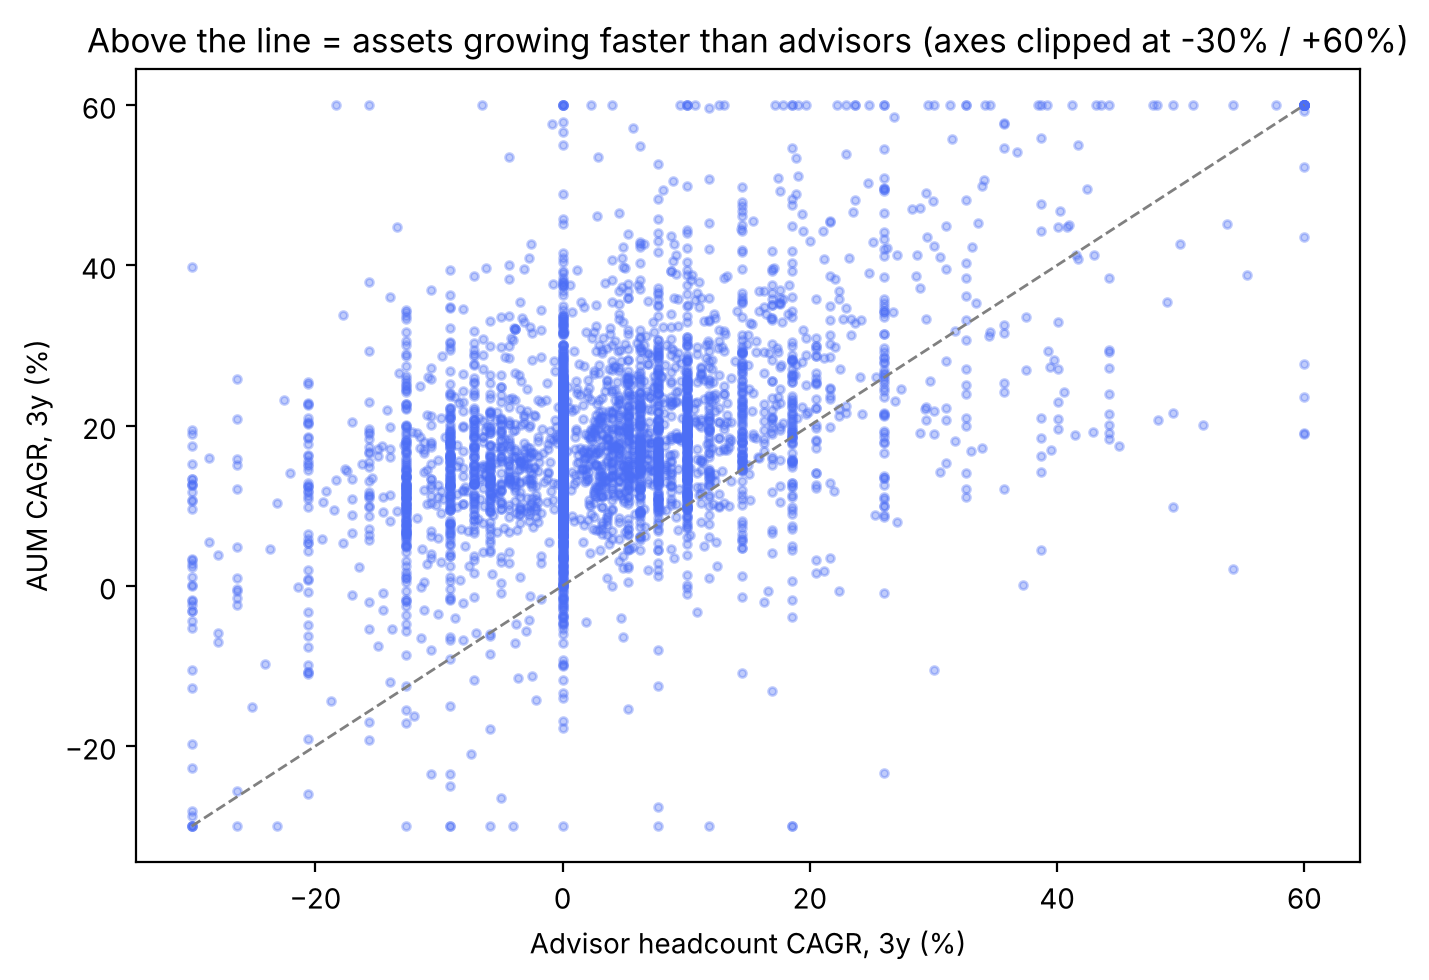

In [19]:
k = 3 if 3 in HORIZONS else HORIZONS[-1]
sub = growth[(growth[f"aum_{k}y_ago"] >= MIN_BASE_AUM) & (growth[f"advisors_{k}y_ago"] >= MIN_ADVISORS) & growth["wealth_focused"]]
share = sub.groupby("segment", observed=False)[f"gap_{k}y"].apply(lambda s: (s > 0).mean() * 100)
print(f"% of wealth managers whose AUM grew faster than advisors over {k} years")
print(share.round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 5))
x, y = sub[f"adv_cagr_{k}y"].clip(-0.3, 0.6) * 100, sub[f"aum_cagr_{k}y"].clip(-0.3, 0.6) * 100
ax.scatter(x, y, s=8, alpha=0.35, color="#4C6EF5")
ax.plot([-30, 60], [-30, 60], color="grey", lw=1, ls="--")
ax.set_xlabel(f"Advisor headcount CAGR, {k}y (%)"); ax.set_ylabel(f"AUM CAGR, {k}y (%)")
ax.set_title("Above the line = assets growing faster than advisors (axes clipped at -30% / +60%)")
plt.tight_layout(); plt.show()

## Timing: who to call right now
The lists above say *who* is stretched. This one says *when*. A wealth manager that grew its advisor team 30%+ in the last year has almost always just acquired other practices. That is the moment it has new advisors, new systems and new processes to bring onto one way of working, which is exactly what a Nevis deployment does. Limited to wealth managers with $1B+ AUM and at least 10 advisors a year ago.

In [20]:
t = growth[(growth["aum"] >= 1e9) & (growth["advisors_1y_ago"] >= 10) & growth["wealth_focused"]].copy()
t["advisor_growth_1y"] = t["advisors"] / t["advisors_1y_ago"] - 1
t = t[t["advisor_growth_1y"] >= 0.30].sort_values("advisor_growth_1y", ascending=False)
cols = ["firm_name", "city", "state", "segment", "advisors_1y_ago", "advisors", "advisor_growth_1y", "aum_1y_ago", "aum", "aum_cagr_1y", "sec_no"]
timing = pct(t, ["advisor_growth_1y", "aum_cagr_1y"])[cols].reset_index(drop=True)
timing.to_csv("nevis_timing_list.csv", index=False)
print(f"{len(t):,} wealth managers ($1B+) grew advisors 30%+ in the last year; saved to nevis_timing_list.csv")
money(timing.head(20))

97 wealth managers ($1B+) grew advisors 30%+ in the last year; saved to nevis_timing_list.csv


,firm_name,city,state,segment,advisors_1y_ago,advisors,advisor_growth_1y,aum_1y_ago ($M),aum ($M),aum_cagr_1y,sec_no
0,"Empower Advisory Group, Llc",Greenwood Village,CO,>$50B,802.00,"6,138.00",665.30,"159,120.00","195,426.00",22.80,801-58105
1,"Bluespring Wealth Management, Llc",Austin,TX,$1B-$10B,14.00,70.00,400.00,"1,489.00","7,823.00",425.50,801-70998
2,"Signal Advisors Wealth, Llc",Detroit,MI,$1B-$10B,10.00,37.00,270.00,"1,353.00","1,689.00",24.90,801-127017
3,"Rbc Securities, Inc.",Los Angeles,CA,$1B-$10B,37.00,124.00,235.10,"1,591.00","1,515.00",-4.80,801-71181
4,Arax Advisory Partners,New York,NY,$10B-$50B,61.00,168.00,175.40,"8,960.00","26,525.00",196.00,801-67165
5,"Triad Wealth Partners, Llc",Lawrence,KS,$1B-$10B,13.00,33.00,153.80,425.00,"1,527.00",259.20,801-128150
6,Rockefeller Capital Management,New York,NY,$10B-$50B,157.00,372.00,136.90,"32,588.00","36,764.00",12.80,801-113009
7,Blueprint Financial Advisors,Charlotte,NC,$1B-$10B,17.00,39.00,129.40,202.00,"1,413.00",601.40,801-121848
8,"Gc Wealth Management Ria, Llc",Cambridge,MA,$1B-$10B,17.00,34.00,100.00,"2,153.00","5,833.00",170.90,801-128318
9,Xypn Sapphire,Bozeman,MT,$1B-$10B,31.00,61.00,96.80,321.00,"1,253.00",290.40,801-118916


## Bringing it together: where I would point sales and deployment first
Each question above points to the same pain Nevis solves: more assets and clients per advisor than the team can comfortably serve. So I combine them into one simple score for wealth managers with at least $1B AUM and 10+ advisors (Nevis's mid-market to enterprise focus):

**Prospect score** = average percentile rank of (3-yr AUM CAGR, AUM per advisor, 3-yr staffing gap). Equal weights, on purpose, so it is easy to explain and easy to change.

In [21]:
k = 3 if 3 in HORIZONS else HORIZONS[-1]
MIN_TEAM = 10   # Nevis sells to firms with real advisor teams, not 3-person family offices
pool = growth[(growth["aum"] >= 1e9) & (growth["advisors"] >= MIN_TEAM) & growth["wealth_focused"]
              & (growth[f"aum_{k}y_ago"] >= MIN_BASE_AUM)].copy()
for c in [f"aum_cagr_{k}y", "aum_per_advisor", f"gap_{k}y"]:
    pool[c + "_rank"] = pool[c].rank(pct=True)
pool["prospect_score"] = pool[[c for c in pool if c.endswith("_rank")]].mean(axis=1).round(3)
cols = ["firm_name", "city", "state", "segment", "aum", "advisors", "aum_per_advisor", f"aum_cagr_{k}y", f"gap_{k}y", "prospect_score", "sec_no"]
shortlist = pct(pool, [f"aum_cagr_{k}y", f"gap_{k}y"]).sort_values("prospect_score", ascending=False)[cols].head(25).reset_index(drop=True)
shortlist.to_csv("nevis_prospect_shortlist.csv", index=False)
print(f"{len(pool):,} wealth managers (>= $1B, 10+ advisors) scored, ${pool['aum'].sum()/1e12:,.1f}T AUM; top 25 saved to nevis_prospect_shortlist.csv")
money(shortlist)

982 wealth managers (>= $1B, 10+ advisors) scored, $18.1T AUM; top 25 saved to nevis_prospect_shortlist.csv


,firm_name,city,state,segment,aum ($M),advisors,aum_per_advisor ($M),aum_cagr_3y,gap_3y,prospect_score,sec_no
0,"A16Z Perennial Management, L.P.",Menlo Park,CA,$1B-$10B,"2,753.00",10.00,275.00,197.10,184.50,0.97,801-127229
1,Cannell & Spears Llc,New York,NY,$1B-$10B,"6,992.00",17.00,411.00,61.10,37.50,0.96,801-67401
2,"Callan Family Office, Llc",Radnor,PA,$10B-$50B,"10,209.00",15.00,681.00,42.30,37.40,0.95,801-122987
3,Pathstone,Englewood,NJ,>$50B,"110,296.00",365.00,302.00,64.40,39.60,0.95,801-70776
4,"Pennington Partners & Co., Llc",Bethesda,MD,$1B-$10B,"5,088.00",10.00,509.00,44.00,36.30,0.95,801-107210
5,"Aptus Capital Advisors, Llc",Fairhope,AL,$10B-$50B,"14,142.00",26.00,544.00,49.30,31.70,0.94,801-107723
6,"Daymark Wealth Partners, Llc",Cincinnati,OH,$1B-$10B,"5,042.00",21.00,240.00,77.10,44.50,0.94,801-124936
7,Bakeravenue,San Francisco,CA,$1B-$10B,"7,725.00",35.00,221.00,59.60,47.70,0.93,801-63576
8,Stelac Advisory Services Llc,New York,NY,$1B-$10B,"6,286.00",10.00,629.00,33.00,38.90,0.93,801-68823
9,Rwa Wealth Partners,Boston,MA,$10B-$50B,"19,795.00",63.00,314.00,45.60,30.20,0.92,801-73098


### Does the shortlist depend on my cutoffs?
The minimums (team size, starting AUM) are judgment calls, so I re-ran the score with looser and stricter settings and measured how much of the top 25 stays the same.

In [22]:
def top25(min_team, min_base):
    pl = growth[(growth["aum"] >= 1e9) & (growth["advisors"] >= min_team) & growth["wealth_focused"]
                & (growth[f"aum_{k}y_ago"] >= min_base)].copy()
    for c in [f"aum_cagr_{k}y", "aum_per_advisor", f"gap_{k}y"]:
        pl[c + "_rank"] = pl[c].rank(pct=True)
    pl["score"] = pl[[c for c in pl if c.endswith("_rank")]].mean(axis=1)
    return set(pl.nlargest(25, "score")["crd"])

base = top25(MIN_TEAM, MIN_BASE_AUM)
rows = []
for team in (5, 10, 20):
    for b in (25e6, 50e6, 100e6):
        rows.append({"min advisors": team, "min starting AUM ($M)": int(b / 1e6),
                     "overlap with my top 25": f"{len(top25(team, b) & base) / 25:.0%}"})
pd.DataFrame(rows)

,min advisors,min starting AUM ($M),overlap with my top 25
0,5,25,60%
1,5,50,60%
2,5,100,60%
3,10,25,100%
4,10,50,100%
5,10,100,100%
6,20,25,56%
7,20,50,56%
8,20,100,56%


**Read:** the starting-AUM cutoff makes no difference. The team-size cutoff matters: at 5 advisors, small family offices come in; at 20, mid-sized firms drop out. I use 10 because Nevis sells to firms with a real advisor team and a deployment worth running, and it is set in one line if Nevis's own cutoff is different.

### Sanity check: where do Nevis's current customers land?
If the score captures the right pain, firms that already bought Nevis should look like this too. I check a few publicly announced Nevis customers.

In [23]:
KNOWN_CUSTOMERS = {"Focus Partners Wealth": r"focus partners wealth", "United Capital": r"united capital financial advisors",
                   "IEQ Capital": r"ieq capital", "Apollon Wealth": r"apollon wealth"}
rows = []
for label, pat in KNOWN_CUSTOMERS.items():
    hit = pool[pool["firm_name"].str.contains(pat, case=False, regex=True, na=False)]
    src = hit if len(hit) else growth[growth["firm_name"].str.contains(pat, case=False, regex=True, na=False)]
    for _, r in src.iterrows():
        rows.append({"customer": label, "firm_name": r["firm_name"], "segment": r["segment"], "aum ($M)": round(r["aum"] / 1e6),
                     "advisors": r["advisors"], f"gap_{k}y (pct pts)": round(r[f"gap_{k}y"] * 100, 1) if pd.notna(r[f"gap_{k}y"]) else np.nan,
                     "score percentile": round(r["prospect_score"] * 100) if "prospect_score" in r and pd.notna(r.get("prospect_score")) else "not in pool"})
pd.DataFrame(rows)

,customer,firm_name,segment,aum ($M),advisors,gap_3y (pct pts),score percentile
0,Focus Partners Wealth,"Focus Partners Wealth, Llc",>$50B,181862,"1,025.00",44.70,91
1,United Capital,United Capital Financial Advisors,$10B-$50B,24647,162.00,45.80,77
2,IEQ Capital,"Ieq Capital, Llc",>$50B,56766,193.00,11.70,75
3,Apollon Wealth,"Apollon Wealth Management, Llc",$10B-$50B,11564,115.00,33.50,78


## Key takeaways for Nevis

1. **The market is wide at the bottom and deep at the top.** 17,263 SEC-registered RIAs as of November 2026. 69% are under $1B but hold 2% of AUM; the 433 firms over $50B hold 79%. That headline is skewed by institutional managers (Vanguard, BlackRock, PIMCO), so the useful lens for Nevis is wealth managers only.
2. **Nevis's core market is about 1,000 firms.** Filtering to wealth managers (offer financial planning, at least half of AUM from individuals) with $1B+ AUM and 10+ advisors leaves roughly 1,000 firms holding about $18T. That is a small enough list for named-account selling, and with pricing on AUM each deployment is large, so deployment capacity matters as much as demand.
3. **Almost everyone is getting more stretched.** Median AUM grew about 13-15% a year across segments, and around 90% of wealth managers grew assets faster than advisor headcount over 3 years. Part of that is markets, but the direction is clear: each advisor is responsible for more assets every year. That is the case for Nevis in one number.
4. **Consolidators are the most stretched, and the best fit.** The biggest gaps sit with roll-ups: Focus Partners Wealth went from 215 to 1,025 advisors and $19B to $182B in 3 years; &Partners, Cetera, Osaic, Merit and Farther show the same pattern. Every acquisition brings new advisors, custodians and processes that need to be standardized fast, which is exactly the deployment problem.
5. **The score finds lookalikes of existing customers.** Publicly announced Nevis customers land high in the prospect score without being used to build it: Focus Partners Wealth (91st percentile), Apollon (78th), United Capital (77th), IEQ (75th). That suggests the rest of the top of the list are real lookalikes worth prioritizing.
6. **How I'd use this in deployment.** Lead sales conversations with capacity (AUM and households per advisor) rather than hours saved, using each firm's own numbers. After go-live, track the same metrics for every customer, and compare live offices against not-yet-live offices of similar size: that is the cleanest answer to "would this have happened anyway?" Add days from kickoff to first live workflow, and every rollout becomes a proof point for the next deal. Look for patterns across many firms rather than one star account: a play that works at ten firms is worth turning into the standard playbook.

## Assumptions and limitations
- **Advisors** = Item 5.B(1) (employees performing investment advisory functions, including research). Form ADV has no exact "advisor" field; this is the closest standard proxy.
- **Clients** = sum of Item 5.D client counts by type + Item 5.C(1) (clients with no regulatory AUM); "fewer than 5" is counted as 2. AUM is regulatory AUM as of the firm's last annual amendment, so it lags the snapshot date by up to a year.
- **Websites**: the SEC monthly export includes only one website per firm and it is often a social profile. Social links are dropped and the firm's own domain is borrowed from another year where possible. The full list of websites is in Form ADV Schedule D 1.I, which would be the next data source to add.
- **Missing months**: the SEC published no data for October and November 2025, so the 1-year comparison uses December 2025 (one month off).
- **AUM growth includes market performance.** Excess growth versus the segment median is shown to separate client wins from market moves.
- **Wealth-manager filter** = offers financial planning (5.G(1)) and at least 50% of AUM from individuals/HNW individuals (5.D(a)(3) + 5.D(b)(3)), using the latest filing. It is deliberately strict: some hybrid firms will be excluded.
- **Firm identity** is tracked by CRD number. Firms that merged into another CRD disappear from growth comparisons; firms that acquired others show a jump (flagged).
- Guardrails ($50M base AUM, 3+ advisors, 50% individual clients) are set in the config cell and can be changed in one place.

## How I used AI
I used Claude to speed up the build: drafting the parsing code, mapping Form ADV item numbers to fields, and structuring the analysis. I then checked the outputs myself: the column mapping printed for each year, the data quality table (firm counts and total AUM by year), the duplicate and negative-value checks, and a spot check of a known firm's history. Every threshold is a visible config value so the reviewer can test the sensitivity.